In [11]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.preprocessing import StandardScaler

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
!pip install -q kagglehub

In [13]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("marian447/retail-store-sales-transactions")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/marian447/retail-store-sales-transactions/versions/4


In [14]:
# Show all files inside the dataset

files = os.listdir(path)

print("Files in dataset:\n")

for file in files:
    print(file)

Files in dataset:

scanner_data.csv


In [15]:
df = pd.read_csv(os.path.join(path, "scanner_data.csv"))

df.head()

,Unnamed: 0,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,1,02/01/2016,2547,1,X52,0EM7L,1.0,3.13
1,2,02/01/2016,822,2,2ML,68BRQ,1.0,5.46
2,3,02/01/2016,3686,3,0H2,CZUZX,1.0,6.35
3,4,02/01/2016,3719,4,0H2,549KK,1.0,5.59
4,5,02/01/2016,9200,5,0H2,K8EHH,1.0,6.88


In [28]:
sales_df = df.copy()

print("Working copy created successfully.")

Working copy created successfully.


In [29]:
sales_df.drop(columns=["Unnamed: 0"], inplace=True)

sales_df["Date"] = pd.to_datetime(
    sales_df["Date"],
    format="%d/%m/%Y"
)

In [30]:
print(sales_df["Quantity"].describe())

print("\nSample unique values:")

print(sales_df["Quantity"].unique()[:20])

count    131706.000000
mean          1.485311
std           3.872667
min           0.010000
25%           1.000000
50%           1.000000
75%           1.000000
max         400.000000
Name: Quantity, dtype: float64

Sample unique values:
[  1.     2.     3.     0.67   4.     5.    60.    28.     8.     0.34
   0.25  90.     0.1    6.    10.    74.     0.33  78.     0.5  100.  ]


In [31]:
sales_df.info()

sales_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131706 entries, 0 to 131705
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   Date            131706 non-null  datetime64[ns]
 1   Customer_ID     131706 non-null  int64         
 2   Transaction_ID  131706 non-null  int64         
 3   SKU_Category    131706 non-null  object        
 4   SKU             131706 non-null  object        
 5   Quantity        131706 non-null  float64       
 6   Sales_Amount    131706 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(2)
memory usage: 7.0+ MB


,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount
0,2016-01-02,2547,1,X52,0EM7L,1.0,3.13
1,2016-01-02,822,2,2ML,68BRQ,1.0,5.46
2,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35
3,2016-01-02,3719,4,0H2,549KK,1.0,5.59
4,2016-01-02,9200,5,0H2,K8EHH,1.0,6.88


In [39]:
sales_df["Year"] = sales_df["Date"].dt.year
sales_df["Month"] = sales_df["Date"].dt.month
sales_df["Month_Name"] = sales_df["Date"].dt.month_name()
sales_df["Day"] = sales_df["Date"].dt.day
sales_df["Day_Name"] = sales_df["Date"].dt.day_name()
sales_df["Week"] = sales_df["Date"].dt.isocalendar().week
sales_df["Quarter"] = sales_df["Date"].dt.quarter

sales_df.columns

Index(['Date', 'Customer_ID', 'Transaction_ID', 'SKU_Category', 'SKU',
       'Quantity', 'Sales_Amount', 'Year', 'Month', 'Month_Name', 'Day',
       'Day_Name', 'Week', 'Quarter'],
      dtype='object')

In [32]:
# ==========================================
# Plot Settings
# ==========================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)

plt.style.use("ggplot")

plt.rcParams.update({
    "figure.figsize": (12,6),
    "figure.dpi": 120,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11
})

sns.set_theme(style="whitegrid")

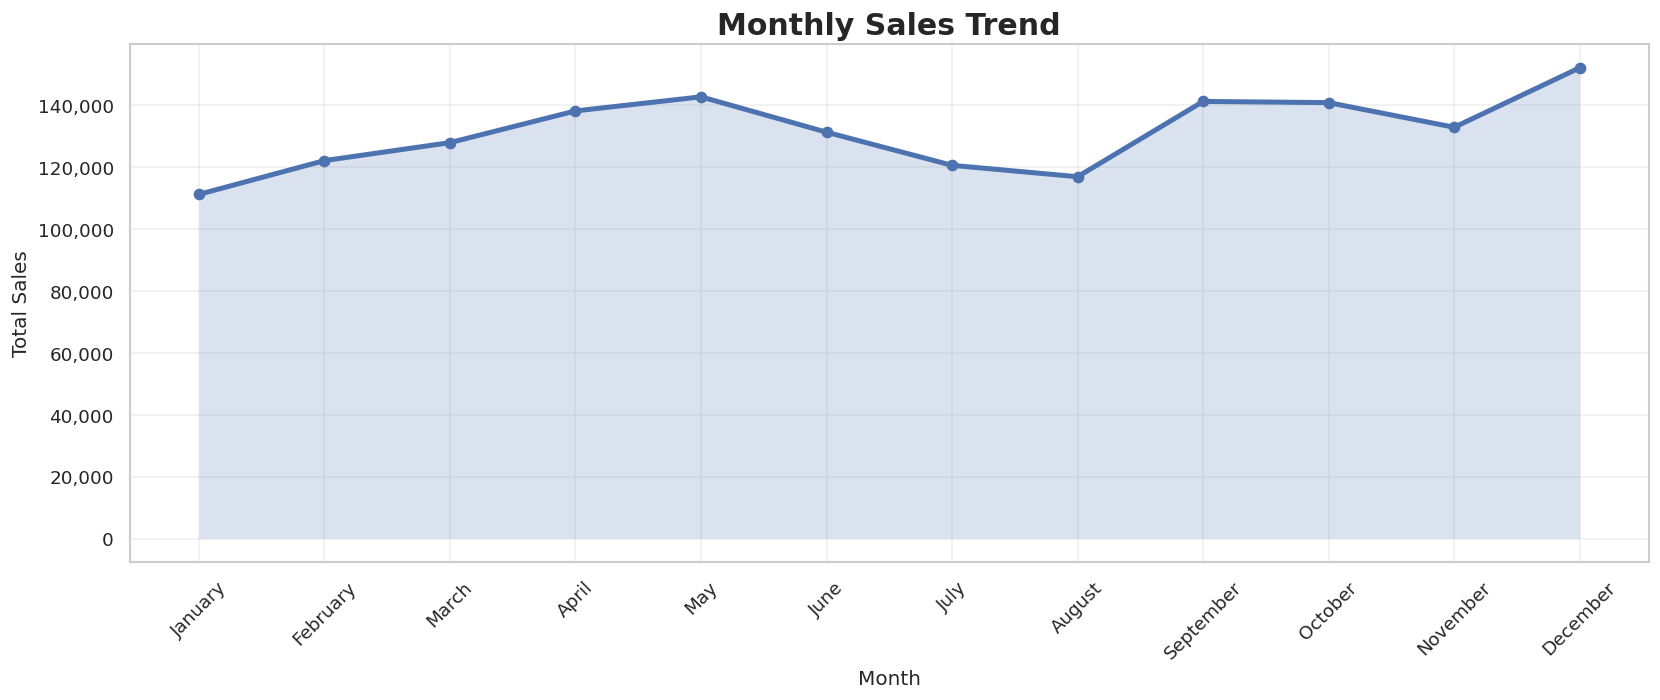

In [40]:
# ==========================================
# Visualization 1: Monthly Sales Trend
# ==========================================

import matplotlib.ticker as mtick

monthly_sales = (
    sales_df.groupby("Month_Name", sort=False)["Sales_Amount"]
    .sum()
    .reindex([
        "January","February","March","April","May","June",
        "July","August","September","October","November","December"
    ])
)

fig, ax = plt.subplots(figsize=(14,6))

ax.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=3
)

ax.fill_between(
    monthly_sales.index,
    monthly_sales.values,
    alpha=0.2
)

ax.set_title("Monthly Sales Trend", fontsize=18, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/monthly_sales_trend.png", dpi=300)
plt.show()

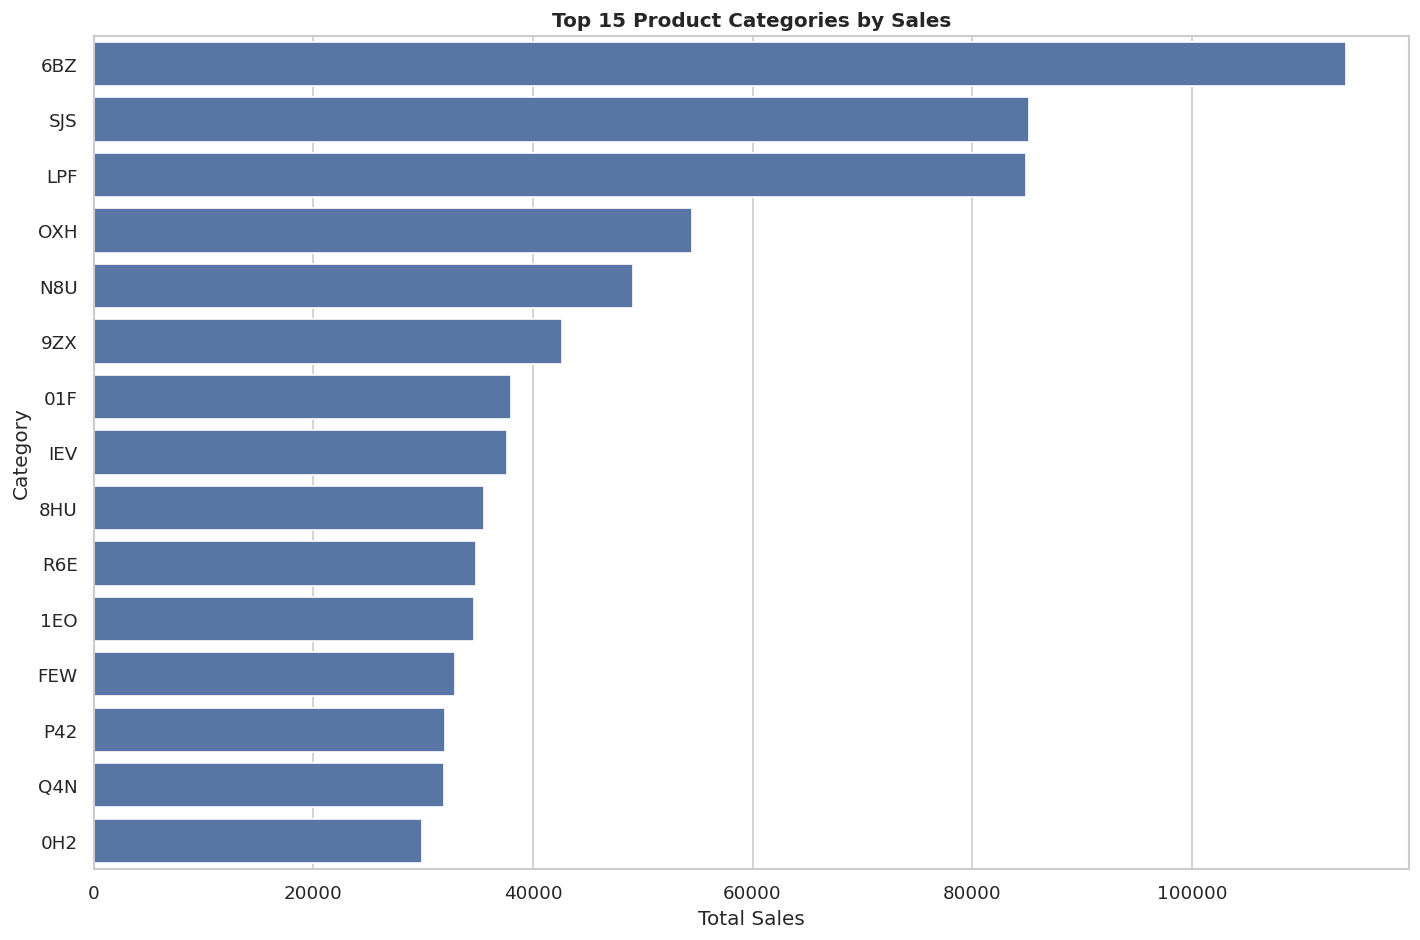

In [41]:
top_categories = (
    sales_df.groupby("SKU_Category")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

fig, ax = plt.subplots(figsize=(12,8))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    ax=ax
)

ax.set_title("Top 15 Product Categories by Sales")
ax.set_xlabel("Total Sales")
ax.set_ylabel("Category")

plt.tight_layout()
plt.savefig("figures/top_categories.png", dpi=300)
plt.show()

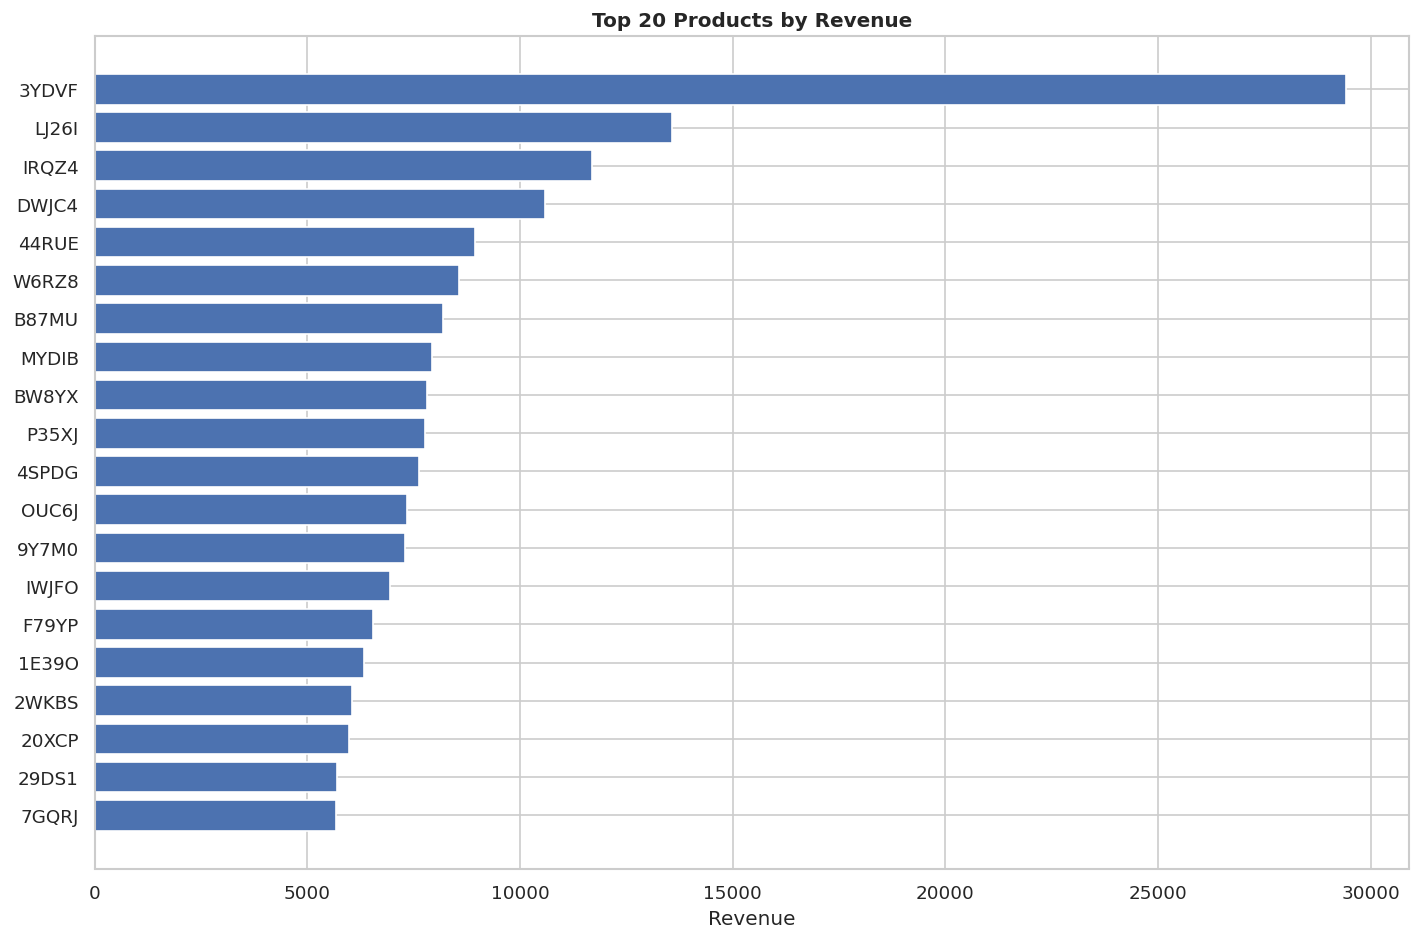

In [42]:
top_products = (
    sales_df.groupby("SKU")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(20)
)

fig, ax = plt.subplots(figsize=(12,8))

ax.barh(
    top_products.index,
    top_products.values
)

ax.invert_yaxis()

ax.set_title("Top 20 Products by Revenue")
ax.set_xlabel("Revenue")

plt.tight_layout()
plt.savefig("figures/top_products.png", dpi=300)
plt.show()

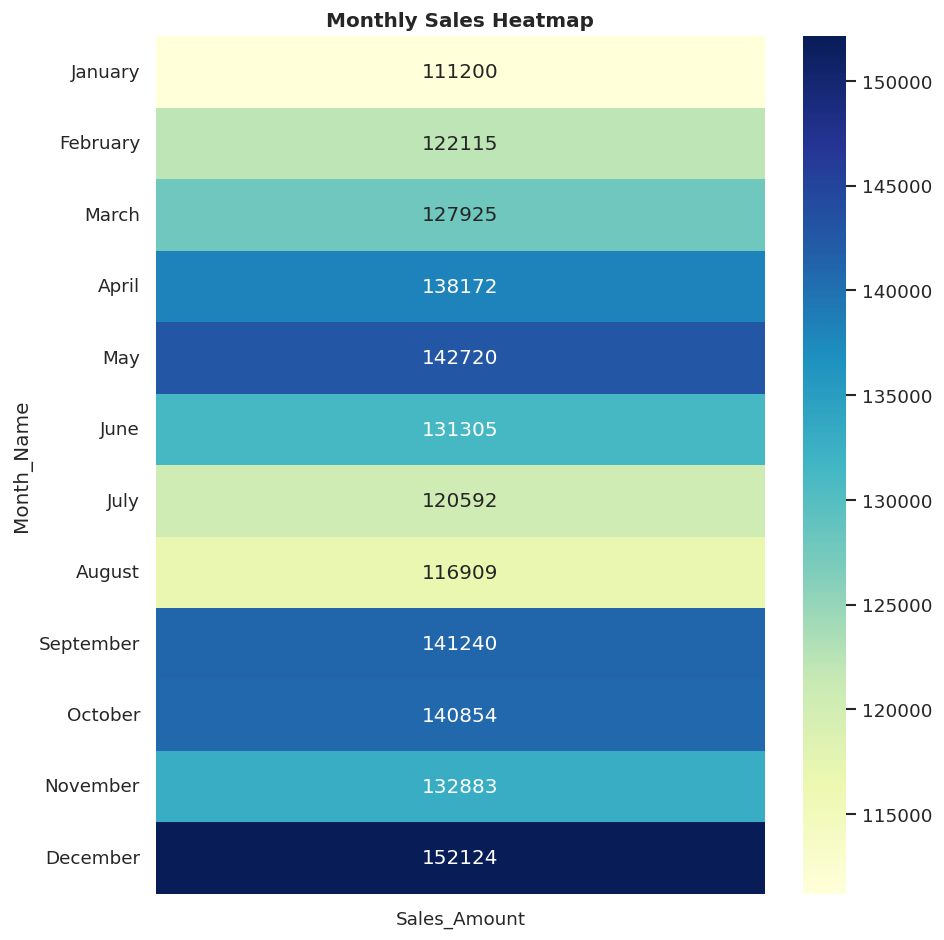

In [43]:
heatmap_data = (
    sales_df.pivot_table(
        values="Sales_Amount",
        index="Month_Name",
        aggfunc="sum"
    )
)

month_order = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

heatmap_data = heatmap_data.reindex(month_order)

plt.figure(figsize=(8,8))

sns.heatmap(
    heatmap_data,
    annot=True,
    cmap="YlGnBu",
    fmt=".0f"
)

plt.title("Monthly Sales Heatmap")

plt.tight_layout()
plt.savefig("figures/monthly_heatmap.png", dpi=300)
plt.show()

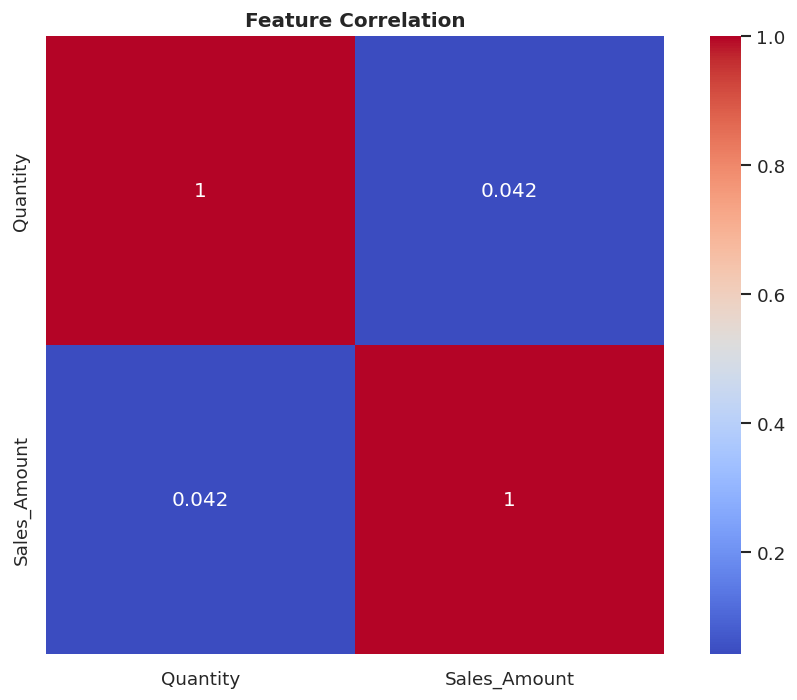

In [44]:
plt.figure(figsize=(8,6))

corr = sales_df[["Quantity","Sales_Amount"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    square=True
)

plt.title("Feature Correlation")

plt.tight_layout()
plt.savefig("figures/correlation.png", dpi=300)
plt.show()

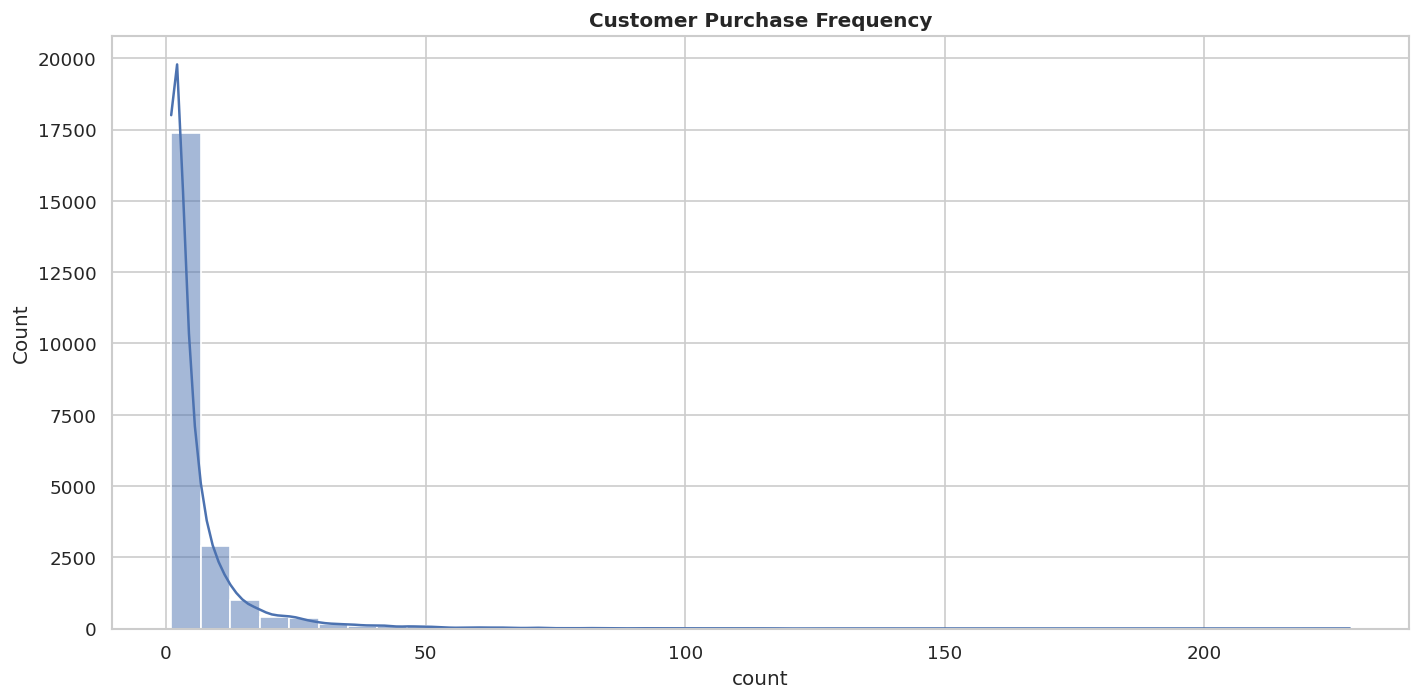

In [45]:
customer_freq = (
    sales_df["Customer_ID"]
    .value_counts()
)

plt.figure(figsize=(12,6))

sns.histplot(
    customer_freq,
    bins=40,
    kde=True
)

plt.title("Customer Purchase Frequency")

plt.tight_layout()
plt.savefig("figures/customer_frequency.png", dpi=300)

plt.show()

In [46]:
import plotly.express as px

weekday_sales = (
    sales_df.groupby("Day_Name")["Sales_Amount"]
    .sum()
    .reindex([
        "Monday","Tuesday","Wednesday",
        "Thursday","Friday","Saturday","Sunday"
    ])
    .reset_index()
)

fig = px.bar(
    weekday_sales,
    x="Day_Name",
    y="Sales_Amount",
    title="Sales by Day of Week",
    text_auto=".2s"
)

fig.write_html("figures/sales_by_weekday.html")

fig.show()

In [47]:
fig = px.scatter(
    sales_df.sample(5000),
    x="Quantity",
    y="Sales_Amount",
    color="SKU_Category",
    title="Quantity vs Sales Amount",
    opacity=0.7
)

fig.write_html("figures/scatter_quantity_sales.html")

fig.show()

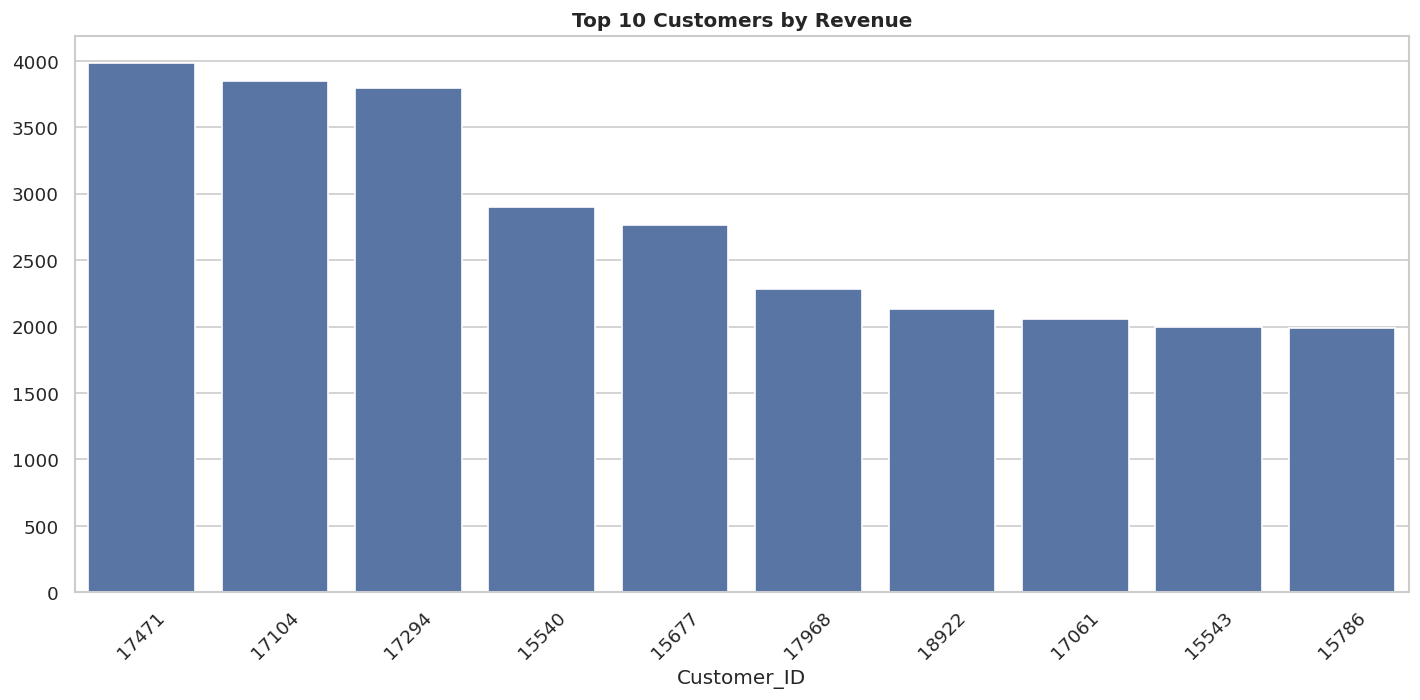

In [48]:
top_customers = (
    sales_df.groupby("Customer_ID")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_customers.index.astype(str),
    y=top_customers.values
)

plt.xticks(rotation=45)

plt.title("Top 10 Customers by Revenue")

plt.tight_layout()
plt.savefig("figures/top_customers.png", dpi=300)

plt.show()

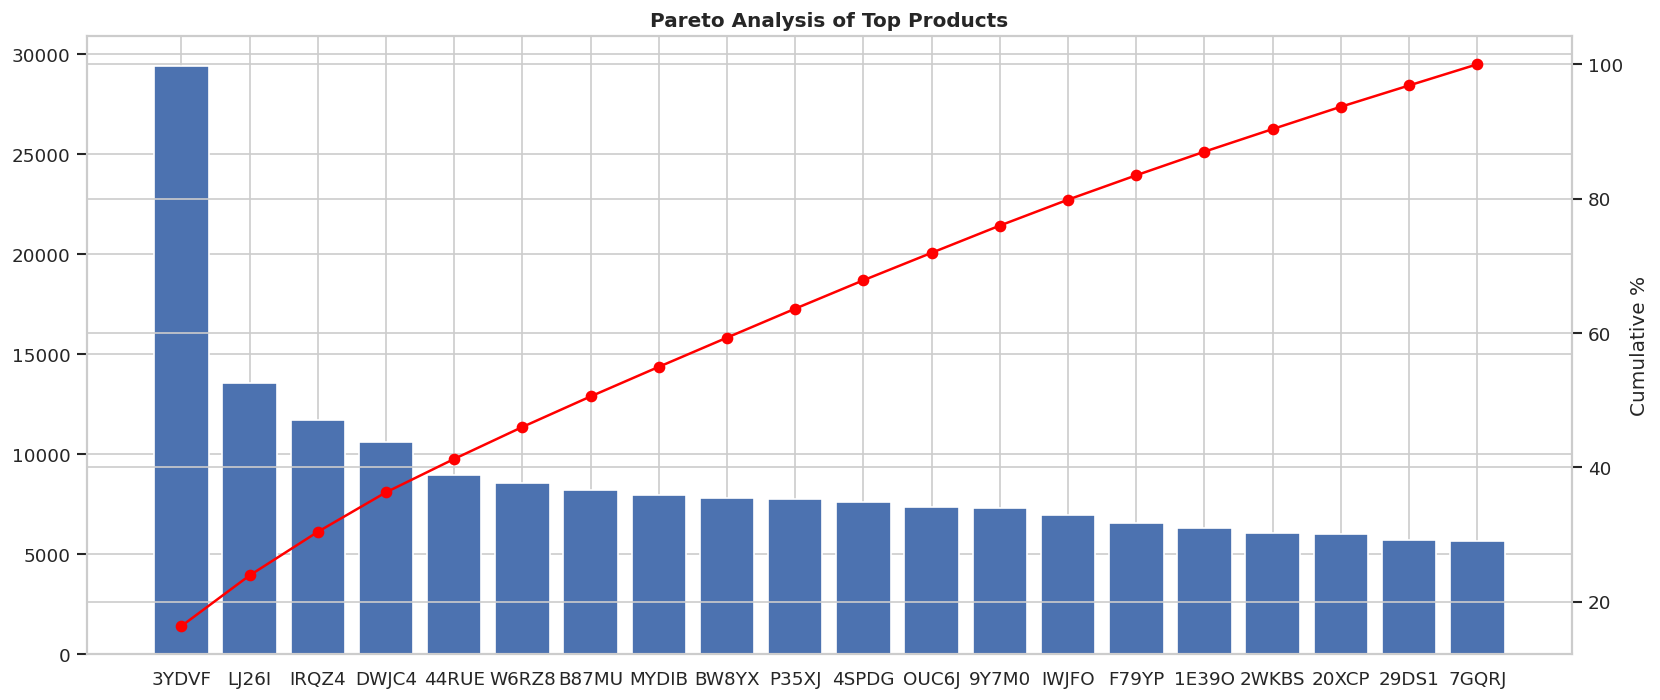

In [49]:
pareto = (
    sales_df.groupby("SKU")["Sales_Amount"]
    .sum()
    .sort_values(ascending=False)
)

pareto = pareto.head(20)

cum = pareto.cumsum() / pareto.sum() * 100

fig, ax1 = plt.subplots(figsize=(14,6))

ax1.bar(pareto.index, pareto.values)

ax2 = ax1.twinx()

ax2.plot(
    pareto.index,
    cum,
    color="red",
    marker="o"
)

ax2.set_ylabel("Cumulative %")

plt.xticks(rotation=90)

plt.title("Pareto Analysis of Top Products")

plt.tight_layout()
plt.savefig("figures/pareto_chart.png", dpi=300)

plt.show()

In [50]:
# Customer & Transaction Features

transaction_value = (
    sales_df.groupby("Transaction_ID")["Sales_Amount"]
    .sum()
    .rename("Transaction_Value")
)

# Number of transactions per customer
purchase_frequency = (
    sales_df.groupby("Customer_ID")["Transaction_ID"]
    .nunique()
    .rename("Purchase_Frequency")
)

# Total spending per customer
customer_spending = (
    sales_df.groupby("Customer_ID")["Sales_Amount"]
    .sum()
    .rename("Customer_Total_Spending")
)

# Average transaction value per customer
avg_transaction = (
    sales_df.groupby("Customer_ID")["Sales_Amount"]
    .mean()
    .rename("Avg_Transaction_Value")
)

sales_df = sales_df.merge(transaction_value, on="Transaction_ID")
sales_df = sales_df.merge(purchase_frequency, on="Customer_ID")
sales_df = sales_df.merge(customer_spending, on="Customer_ID")
sales_df = sales_df.merge(avg_transaction, on="Customer_ID")

In [51]:
# Product & Time Features


# Product popularity
product_popularity = (
    sales_df.groupby("SKU")["Quantity"]
    .sum()
    .rename("Product_Popularity")
)

# Category total sales
category_sales = (
    sales_df.groupby("SKU_Category")["Sales_Amount"]
    .sum()
    .rename("Category_Total_Sales")
)

sales_df = sales_df.merge(product_popularity, on="SKU")
sales_df = sales_df.merge(category_sales, on="SKU_Category")

# Customer tenure
first_purchase = (
    sales_df.groupby("Customer_ID")["Date"]
    .min()
    .rename("First_Purchase")
)

sales_df = sales_df.merge(first_purchase, on="Customer_ID")

sales_df["Customer_Tenure_Days"] = (
    sales_df["Date"] - sales_df["First_Purchase"]
).dt.days

# Weekend indicator
sales_df["Is_Weekend"] = (
    sales_df["Day_Name"]
    .isin(["Saturday", "Sunday"])
    .astype(int)
)

In [52]:
print(f"Dataset Shape: {sales_df.shape}")

new_features = [
    "Transaction_Value",
    "Purchase_Frequency",
    "Customer_Total_Spending",
    "Avg_Transaction_Value",
    "Product_Popularity",
    "Category_Total_Sales",
    "Customer_Tenure_Days",
    "Is_Weekend"
]

print("\nNew Features Created:")
for feature in new_features:
    print(f"✓ {feature}")

sales_df.head()

Dataset Shape: (131706, 23)

New Features Created:
✓ Transaction_Value
✓ Purchase_Frequency
✓ Customer_Total_Spending
✓ Avg_Transaction_Value
✓ Product_Popularity
✓ Category_Total_Sales
✓ Customer_Tenure_Days
✓ Is_Weekend


,Date,Customer_ID,Transaction_ID,SKU_Category,SKU,Quantity,Sales_Amount,Year,Month,Month_Name,Day,Day_Name,Week,Quarter,Transaction_Value,Purchase_Frequency,Customer_Total_Spending,Avg_Transaction_Value,Product_Popularity,Category_Total_Sales,First_Purchase,Customer_Tenure_Days,Is_Weekend
0,2016-01-02,2547,1,X52,0EM7L,1.0,3.13,2016,1,January,2,Saturday,53,1,3.13,7,121.36,7.585000,28.0,12769.07,2016-01-02,0,1
1,2016-01-02,822,2,2ML,68BRQ,1.0,5.46,2016,1,January,2,Saturday,53,1,5.46,3,20.40,4.080000,270.0,11220.75,2016-01-02,0,1
2,2016-01-02,3686,3,0H2,CZUZX,1.0,6.35,2016,1,January,2,Saturday,53,1,6.35,15,405.44,8.108800,638.0,29875.14,2016-01-02,0,1
3,2016-01-02,3719,4,0H2,549KK,1.0,5.59,2016,1,January,2,Saturday,53,1,5.59,10,420.72,8.951489,166.0,29875.14,2016-01-02,0,1
4,2016-01-02,9200,5,0H2,K8EHH,1.0,6.88,2016,1,January,2,Saturday,53,1,6.88,2,18.01,9.005000,72.0,29875.14,2016-01-02,0,1


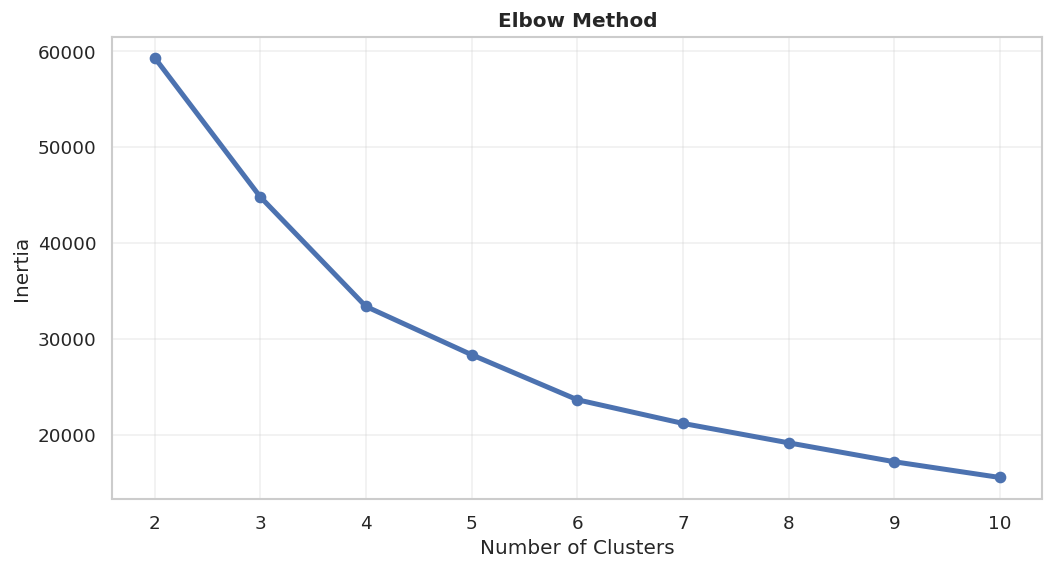

Silhouette Score : 0.578



Cluster Summary


,Customer_Total_Spending,Purchase_Frequency,Avg_Transaction_Value,Customer_Tenure_Days
Cluster,,,,
0,27.35,1.49,9.52,13.91
1,123.45,5.51,11.14,177.89
2,752.76,19.54,16.88,244.63
3,212.55,1.55,92.00,25.35


In [53]:
# MODEL 1 : CUSTOMER SEGMENTATION USING K-MEANS, Unsupervised Learning

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

import matplotlib.pyplot as plt
import plotly.express as px


customer_df = (
    sales_df.groupby("Customer_ID")
    .agg({
        "Customer_Total_Spending":"first",
        "Purchase_Frequency":"first",
        "Avg_Transaction_Value":"first",
        "Customer_Tenure_Days":"max"
    })
    .reset_index()
)

features = [
    "Customer_Total_Spending",
    "Purchase_Frequency",
    "Avg_Transaction_Value",
    "Customer_Tenure_Days"
]

X = customer_df[features]

# Scale Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# Elbow Method
inertia = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(10,5))

plt.plot(
    range(2,11),
    inertia,
    marker="o",
    linewidth=3
)

plt.title("Elbow Method")

plt.xlabel("Number of Clusters")

plt.ylabel("Inertia")

plt.grid(alpha=0.3)

plt.savefig(
    "figures/elbow_method.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Train Final Model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

customer_df["Cluster"] = kmeans.fit_predict(X_scaled)


# Evaluation
score = silhouette_score(
    X_scaled,
    customer_df["Cluster"]
)

print("="*50)
print(f"Silhouette Score : {score:.3f}")
print("="*50)


# PCA Visualization
pca = PCA(n_components=2)

components = pca.fit_transform(X_scaled)

customer_df["PCA1"] = components[:,0]
customer_df["PCA2"] = components[:,1]

fig = px.scatter(
    customer_df,
    x="PCA1",
    y="PCA2",
    color=customer_df["Cluster"].astype(str),
    hover_data=[
        "Customer_ID",
        "Customer_Total_Spending",
        "Purchase_Frequency"
    ],
    title="Customer Segmentation using K-Means"
)

fig.write_html("figures/customer_segmentation.html")

fig.show()

# -------------------------
# Cluster Summary
# -------------------------

cluster_summary = (
    customer_df
    .groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("\nCluster Summary")

display(cluster_summary)

,Model,MAE,RMSE,R² Score
2,Gradient Boosting,7.179886,15.540592,0.337369
0,Linear Regression,6.674646,15.979432,0.299418
1,Random Forest,7.611543,16.106180,0.288260


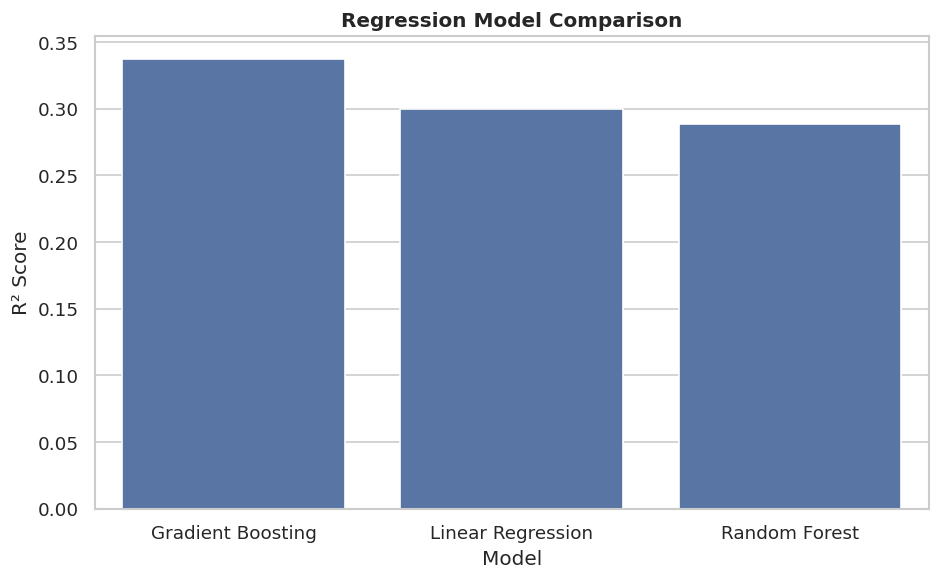

In [61]:
# MODEL 2 : SALES PREDICTION, Supervised Learning, Linear Regression, Random Forest Regressor, Gradient Boosting Regressor


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.preprocessing import OneHotEncoder

# Select Features

model_df = sales_df.copy()

features = [
    "Quantity",
    "SKU_Category",
    "Month",
    "Day",
    "Is_Weekend",
    "Purchase_Frequency"
]
target = "Sales_Amount"

X = model_df[features]
y = model_df[target]


# Categorical / Numerical
categorical = [
    "SKU_Category",

]

numerical = [
    "Quantity",
    "Month",
    "Day",
    "Is_Weekend",
    "Purchase_Frequency"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical
        ),
        (
            "num",
            "passthrough",
            numerical
        )
    ]
)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Models
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
    n_estimators=50,
    max_depth=10,
    random_state=42,
    n_jobs=-1
     ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []


# Training Loop
for name, model in models.items():

    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    r2 = r2_score(y_test, pred)

    results.append([
        name,
        mae,
        rmse,
        r2
    ])

# Results
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "RMSE",
        "R² Score"
    ]
)

results_df = results_df.sort_values(
    by="R² Score",
    ascending=False
)

display(results_df)

# Visualization
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R² Score"
)

plt.title("Regression Model Comparison")

plt.tight_layout()

plt.savefig(
    "figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# **Business Insights**

- The exploratory analysis identified the best-performing product categories and highlighted seasonal sales patterns.
- Customer segmentation grouped shoppers into distinct clusters based on their spending behavior and purchase frequency, enabling more targeted marketing strategies.
- The regression models demonstrated that purchase quantity, product category, and customer purchasing behavior are important factors influencing sales.
- These insights can help businesses optimize inventory management, improve customer retention, and support data-driven decision-making.

# **Conclusion**

This project developed an end-to-end retail sales analytics solution using Python and machine learning. The workflow included data cleaning, exploratory data analysis, feature engineering, customer segmentation using K-Means clustering, and sales prediction using regression models.

The results demonstrate how data science techniques can uncover customer behavior, identify sales trends, and support business decision-making. This project showcases practical skills in data preprocessing, visualization, machine learning, and business analytics, making it suitable for a Junior Data Scientist portfolio.